In [1]:
import matplotlib 
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import pandas as pd
import re

from mpl_toolkits.axes_grid1 import ImageGrid

In [4]:
# Improved approach: Extract numerical data from TikZ file after \addplot

data_blocks = []
recording = False
with open("../../data/tacho/examplesession200.tikz") as tikz_content:
    for line in tikz_content:
        line = line.strip()

        if line.startswith(r"\addplot"):
            recording = True  # Start recording data points
            current_block = []
        elif recording and line.startswith("};"):  # End of data block
            recording = False
            data_blocks.append(current_block)
        elif recording:
            current_block.append(line)

# Process extracted data and convert to CSV


for i, block in enumerate(data_blocks):
    all_data = []
    csv_path = f'../../data/tacho/extracted_plot_data{i}.csv'
    for line in block:
        # Split by whitespace and check for valid numeric entries
        parts = line.split()
        if len(parts) == 2:
            try:
                x, y = float(parts[0]), float(parts[1])
                all_data.append((x, y))
            except ValueError:
                continue  # Skip invalid lines
    df = pd.DataFrame(all_data, columns=['t', 'y'])
    df.to_csv(csv_path, index=False)

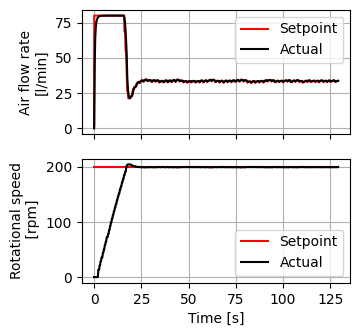

In [6]:
# Load data
file_path = "../../data/tacho/extracted_plot_data0.csv"
df = pd.read_csv(file_path, sep=",")
file_path1 = "../../data/tacho/extracted_plot_data1.csv"
df1 = pd.read_csv(file_path1, sep=",")

file_path2 = "../../data/tacho/extracted_plot_data2.csv"
df2 = pd.read_csv(file_path2, sep=",")
file_path3 = "../../data/tacho/extracted_plot_data3.csv"
df3 = pd.read_csv(file_path3, sep=",")


mm = 1/25.4
# Plot data
# fig0, axes = plt.subplots(nrows=2, ncols=1, figsize=(181*mm, 90*mm), sharex=True) # figsize: pixel size for latex
fig0, axes = plt.subplots(nrows=2, ncols=1, figsize=(88*mm, 90*mm), sharex=True, dpi=100) # figsize: pixel size for latex
plt.rcParams.update({'font.size': 10})
axes[0].plot(df['t'], df['y'], marker=None, linestyle='-', color='red', label='Setpoint')
axes[0].plot(df1['t'], df1['y'], marker=None, linestyle='-', color='black', label='Actual')

axes[0].set_ylabel("Air flow rate\n[l/min]")

axes[1].plot(df2['t'], df2['y'], marker=None, linestyle='-', color='red', label='Setpoint')
axes[1].plot(df3['t'], df3['y'], marker=None, linestyle='-', color='black', label='Actual')

axes[1].set_ylabel("Rotational speed\n [rpm]")

axes[-1].set_xlabel("Time [s]")
for axis in axes:
    axis.legend()
    axis.grid()
    

plt.savefig(f'Fig7ab.svg')

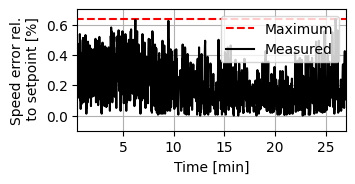

In [7]:
# Load data
file_path = "../../data/tacho/extracted_plot_data4.csv"
df = pd.read_csv(file_path, sep=",")
file_path1 = "../../data/tacho/extracted_plot_data5.csv"
df1 = pd.read_csv(file_path1, sep=",")

# Plot data
# plt.rcParams.update({'font.size': 10, 'font.family': 'Times New Roman'})
plt.rcParams.update({'font.size': 10})
fig0, axes = plt.subplots(nrows=1, ncols=1, figsize=(88*mm, 40*mm), sharex=True) # figsize: pixel size for latex
axes.plot(df['t'] / 60, df['y'], marker=None, linestyle='--', color='red', label='Maximum')
axes.plot(df1['t'] / 60, df1['y'], marker=None, linestyle='-', color='black', label='Measured')
axes.set_ylabel("Speed error rel.\n to setpoint [%]")

axes.set_xlabel("Time [min]")
axes.grid()
axes.set_ylim((-0.1, 0.7))
axes.set_xlim((0.5, 27))
axes.legend()


plt.savefig(f'Fig7c.svg')

### Evaluation of IDEA protocol for BEAT

In [ ]:
# 200rpm, fast
prot = r'../../data/mr_simulationprotocols/003 - CCW_7_cor_venc150_200rpm_135cms_10avgs_fast/SimulationProtocol.txt'
te_shift = 0

# 200rpm, slow
# prot = r'../../data/mr_simulationprotocols/004 - CCW_8_cor_venc150_200rpm_135cms_10avgs_slow/SimulationProtocol.txt'
# te_shift = -10

# # 500rpm, fast
# prot = r'../../data/mr_simulationprotocols/009 - CCW_13_cor_venc400_500rpm_135cms_10avgs_fast/SimulationProtocol.txt'
# te_shift = 80
# 500rpm, slow
# prot = r'../../data/mr_simulationprotocols/010 - CCW_14_cor_venc400_500rpm_135cms_10avgs_slow/SimulationProtocol.txt'
# te_shift = -10

In [7]:
df = pd.read_csv(prot, header=5, sep='\t', dtype=np.float64, skip_blank_lines=True, skipinitialspace=True)

df.rename(columns=lambda c: re.sub('[^a-zA-Z0-9 , . ( ) -]', '', c), inplace=True)

df.rename(columns=lambda x: x.strip(), inplace=True)

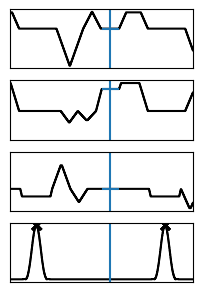

In [8]:
plt.rcParams.update({'font.size': 10})
fig0, ax = plt.subplots(nrows=4, ncols=1, figsize=(60*mm, 90*mm), sharex=True) # figsize: pixel size for latex

plot1 = ax[0].plot(df['X Gradient'], color='black')
plot2 = ax[2].plot(df['Y Gradient'], color='black')
plot3 = ax[1].plot(df['Z Gradient'], color='black')
plot4 = ax[3].plot(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'], color='black')

adc_events = np.diff(df['ADC Signal Data'])
adc_events_time = np.arange(adc_events.shape[0]) + 0.5

adc_events_begin = np.argwhere(adc_events == 1).reshape([-1])
adc_events_end = np.argwhere(adc_events == -1).reshape([-1])

# if the simulation cut off an ADC starting or ending event, we only consider ADCs which start and end in the simulation timespan
min_events = np.minimum(adc_events_begin.shape[0], adc_events_end.shape[0])
adc_events_begin = adc_events_begin[:min_events]
adc_events_end = adc_events_end[:min_events]


# assuming no asymmetric echo
adc_echoes_idx = (adc_events_end - adc_events_begin) / 2 + adc_events_begin

for adc_event_begin, adc_event_end, adc_echo_idx in zip(adc_events_begin, adc_events_end, adc_echoes_idx):
    ax[0].hlines(df['X Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[2].hlines(df['Y Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[1].hlines(df['Z Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    # for axis in ax:
        # axis.axvspan(adc_event_begin, adc_event_end, facecolor='orange')

for adc_echo_idx in adc_echoes_idx:
    for axis in ax:
        axis.axvline(adc_echo_idx)
        
rf_max = df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].max()
time_vec = np.arange(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].shape[0])
rf_centers = np.argwhere(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'] == rf_max).reshape([-1])
ax[3].scatter(rf_centers, df['RF-Signal (ch. 1, 1H, 123.2 MHz)'][rf_centers], marker='x', color='black')


# ax[0].set_ylabel('Phase encoding\ngradient [mT/m]')
# ax[1].set_ylabel('Slice encoding\ngradient [mT/m]')
# ax[2].set_ylabel('Frequency encoding\ngradient [mT/m]')
# ax[3].set_ylabel('RF [a.u.]')

####
for i in range(4):
    ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
    # ax[i].spines['bottom'].set_color('k')
    # ax[i].spines['left'].set_color('k')
    # ax[i].spines['right'].set_color('k')
    # ax[i].spines['top'].set_color('k')
    ax[i].set_yticks(())

# plt.savefig("full_gradients" + save_format)

# ax[0].set_xlim(left=adc_echoes_idx[-2], right=adc_echoes_idx[-1])
ax[0].set_xlim(left=rf_centers[-31]*0.99, right=rf_centers[-1]*1.01)

ax[0].set_xticks(())


plt.savefig("gradients_BEAT.svg")

### Evaluation of IDEA protocol for BERNSTEIN

In [9]:
prot = r'SimulationProtocol_Bernstein.txt'

In [10]:
df = pd.read_csv(prot, header=5, sep='\t', dtype=np.float64, skip_blank_lines=True, skipinitialspace=True)

df.rename(columns=lambda c: re.sub('[^a-zA-Z0-9 , . ( ) -]', '', c), inplace=True)

df.rename(columns=lambda x: x.strip(), inplace=True)

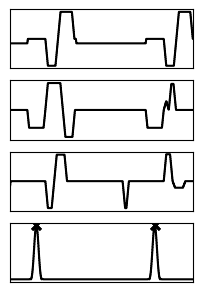

In [11]:
plt.rcParams.update({'font.size': 10})
fig0, ax = plt.subplots(nrows=4, ncols=1, figsize=(60*mm, 90*mm), sharex=True) # figsize: pixel size for latex

plot1 = ax[0].plot(df['X Gradient'], color='black')
plot2 = ax[2].plot(df['Y Gradient'], color='black')
plot3 = ax[1].plot(df['Z Gradient'], color='black')
plot4 = ax[3].plot(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'], color='black')

adc_events = np.diff(df['ADC Signal Data'])
adc_events_time = np.arange(adc_events.shape[0]) + 0.5

adc_events_begin = np.argwhere(adc_events == 1).reshape([-1])
adc_events_end = np.argwhere(adc_events == -1).reshape([-1])

# if the simulation cut off an ADC starting or ending event, we only consider ADCs which start and end in the simulation timespan
min_events = np.minimum(adc_events_begin.shape[0], adc_events_end.shape[0])
adc_events_begin = adc_events_begin[:min_events]
adc_events_end = adc_events_end[:min_events]


# assuming no asymmetric echo
adc_echoes_idx = (adc_events_end - adc_events_begin) / 2 + adc_events_begin

for adc_event_begin, adc_event_end, adc_echo_idx in zip(adc_events_begin, adc_events_end, adc_echoes_idx):
    ax[0].hlines(df['X Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[2].hlines(df['Y Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[1].hlines(df['Z Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    # for axis in ax:
        # axis.axvspan(adc_event_begin, adc_event_end, facecolor='orange')

for adc_echo_idx in adc_echoes_idx:
    for axis in ax:
        axis.axvline(adc_echo_idx)
        
rf_max = df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].max()
time_vec = np.arange(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].shape[0])
rf_centers = np.argwhere(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'] == rf_max).reshape([-1])
ax[3].scatter(rf_centers, df['RF-Signal (ch. 1, 1H, 123.2 MHz)'][rf_centers], marker='x', color='black')


# ax[0].set_ylabel('Phase encoding\ngradient [mT/m]')
# ax[1].set_ylabel('Slice encoding\ngradient [mT/m]')
# ax[2].set_ylabel('Frequency encoding\ngradient [mT/m]')
# ax[3].set_ylabel('RF [a.u.]')

####
for i in range(4):
    ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
    # ax[i].spines['bottom'].set_color('k')
    # ax[i].spines['left'].set_color('k')
    # ax[i].spines['right'].set_color('k')
    # ax[i].spines['top'].set_color('k')
    ax[i].set_yticks(())

# plt.savefig("full_gradients" + save_format)

# ax[0].set_xlim(left=adc_echoes_idx[-2], right=adc_echoes_idx[-1])
ax[0].set_xlim(left=rf_centers[-20]*0.9, right=rf_centers[-1]*1.1)

ax[0].set_xticks(())


plt.savefig("gradients_BERNSTEIN.svg")

### Evaluation of pulseq protocol for CMR (illustrative sequence)

In [12]:
prot = r'C:\Users\dillin01\Documents\rotphantomPUB\rotationalphantom\cmrseq_venc100_bernstein_BW892\SimulationProtocol.txt'

In [13]:
df = pd.read_csv(prot, header=5, sep='\t', dtype=np.float64, skip_blank_lines=True, skipinitialspace=True)

df.rename(columns=lambda c: re.sub('[^a-zA-Z0-9 , . ( ) -]', '', c), inplace=True)

df.rename(columns=lambda x: x.strip(), inplace=True)

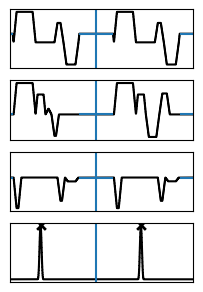

In [14]:
plt.rcParams.update({'font.size': 10})
fig0, ax = plt.subplots(nrows=4, ncols=1, figsize=(60*mm, 90*mm), sharex=True) # figsize: pixel size for latex

plot1 = ax[0].plot(df['X Gradient (GPA 0)'], color='black')
plot2 = ax[2].plot(df['Y Gradient (GPA 0)'], color='black')
plot3 = ax[1].plot(df['Z Gradient (GPA 0)'], color='black')
plot4 = ax[3].plot(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'], color='black')

adc_events = np.diff(df['ADC Signal Data'])
adc_events_time = np.arange(adc_events.shape[0]) + 0.5

adc_events_begin = np.argwhere(adc_events == 1).reshape([-1])
adc_events_end = np.argwhere(adc_events == -1).reshape([-1])

# if the simulation cut off an ADC starting or ending event, we only consider ADCs which start and end in the simulation timespan
min_events = np.minimum(adc_events_begin.shape[0], adc_events_end.shape[0])
adc_events_begin = adc_events_begin[:min_events]
adc_events_end = adc_events_end[:min_events]


# assuming no asymmetric echo
adc_echoes_idx = (adc_events_end - adc_events_begin) / 2 + adc_events_begin

for adc_event_begin, adc_event_end, adc_echo_idx in zip(adc_events_begin, adc_events_end, adc_echoes_idx):
    ax[0].hlines(df['X Gradient (GPA 0)'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[2].hlines(df['Y Gradient (GPA 0)'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[1].hlines(df['Z Gradient (GPA 0)'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    # for axis in ax:
        # axis.axvspan(adc_event_begin, adc_event_end, facecolor='orange')

for adc_echo_idx in adc_echoes_idx:
    for axis in ax:
        axis.axvline(adc_echo_idx)
        
rf_max = df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].max()
time_vec = np.arange(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].shape[0])
rf_centers = np.argwhere(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'] == rf_max).reshape([-1])
ax[3].scatter(rf_centers, df['RF-Signal (ch. 1, 1H, 123.2 MHz)'][rf_centers], marker='x', color='black')


# ax[0].set_ylabel('Phase encoding\ngradient [mT/m]')
# ax[1].set_ylabel('Slice encoding\ngradient [mT/m]')
# ax[2].set_ylabel('Frequency encoding\ngradient [mT/m]')
# ax[3].set_ylabel('RF [a.u.]')

####
for i in range(4):
    ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
    # ax[i].spines['bottom'].set_color('k')
    # ax[i].spines['left'].set_color('k')
    # ax[i].spines['right'].set_color('k')
    # ax[i].spines['top'].set_color('k')
    ax[i].set_yticks(())

# plt.savefig("full_gradients" + save_format)

# ax[0].set_xlim(left=adc_echoes_idx[-2], right=adc_echoes_idx[-1])
ax[0].set_xlim(left=rf_centers[-40]*0.98, right=rf_centers[-40]*1.1)

ax[0].set_xticks(())


plt.savefig("gradients_CMR_illustrative.svg")

### Plots for mathematical justification

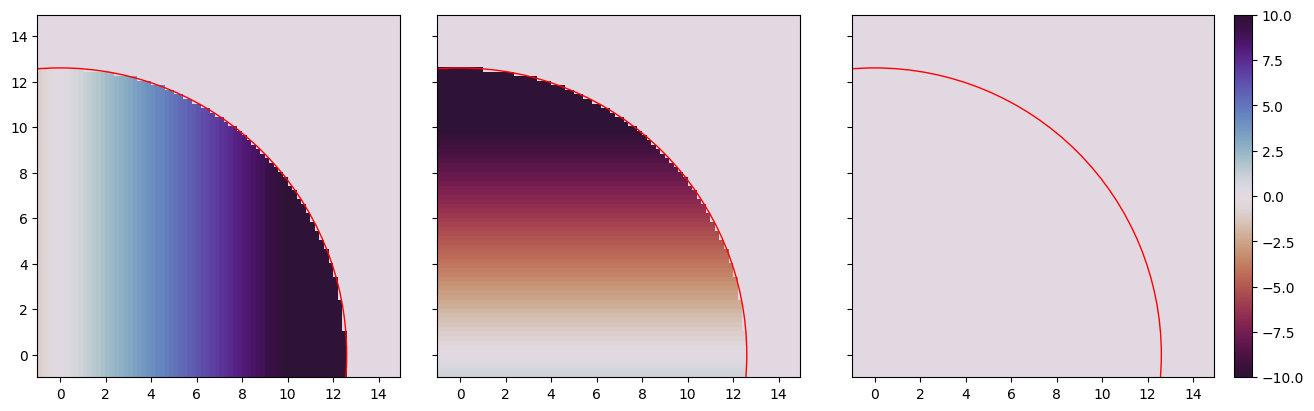

In [138]:
from matplotlib.colors import LinearSegmentedColormap

# Shape of matrices
shape = 224
imgsize = 22.4
# Phantom radius
r = np.linspace(-imgsize, imgsize, shape)
# r_phan = 6.47*2 #cm
r_phan = 6.3*2 #cm

center_pre = (0, 0) # Circle center

cmap = matplotlib.colormaps.get_cmap('twilight')  # viridis is the default colormap for imshow

# Number of colors to sample
N = 256
# Convert to a list of colors
colors = cmap(np.linspace(0, 1, N))

# Shift the colormap by 0.5 (center goes to the ends)
shifted_colors = np.roll(colors, N // 2, axis=0)

# Create a new colormap
shifted_cmap = LinearSegmentedColormap.from_list('shifted_twilight', shifted_colors)

cmap = shifted_cmap
# cmap.set_bad(color='white')
cmap.set_bad(color=cmap(0.5))

xan, yan = np.meshgrid(np.linspace(-imgsize,imgsize,shape),np.linspace(-imgsize,imgsize,shape))

dist_from_center2 = np.sqrt(xan**2 + yan**2)
mask2 = dist_from_center2 <= r_phan
mask2 = np.ones_like(xan)
mask2[~(dist_from_center2 <= r_phan).astype(bool)] = np.nan

xanccw = xan + 0 # eddy current shift

fig0, ax0 = plt.subplots(1, 3, figsize=(13, 4), layout="constrained", sharex=True, sharey=True)

ax0[0].imshow(xan*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-10, vmax=10, cmap=cmap)
circle = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[0].add_patch(circle)

ax0[1].imshow(yan*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-10, vmax=10, cmap=cmap)
circle2 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[1].add_patch(circle2)

im2 = ax0[2].imshow(xan*mask2 - xanccw*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-10, vmax=10, cmap=cmap)
circle3 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[2].add_patch(circle3)

fig0.colorbar(im2)
ax0[0].set_xlim(-1,imgsize/1.5)
ax0[0].set_ylim(-1,imgsize/1.5)

plt.savefig('analytical_vel_zoom.svg')

plt.show()

1.7840000000000003
1.7840000000000003
1.0


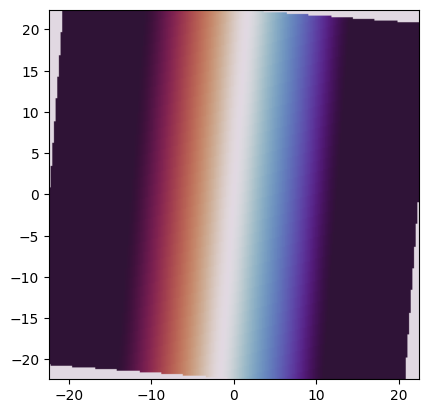

In [173]:
from scipy import ndimage

# 0
# rotation_time = 8.76
# tgx
rotation_time = 4.248
# tgy
# rotation_time = 6.081
# te
# rotation_time = 0.0

# rotation_time = 5.82

# homogeneous coordinate matrix, no rotation, no shift
rot = np.eye(2, 2)
rot_angle = rotation_time * (2*np.pi) / 360
rot[0, 0] = np.cos(rot_angle)
rot[0, 1] = -np.sin(rot_angle)
rot[1, 0] = np.sin(rot_angle)
rot[1, 1] = np.cos(rot_angle)

# center = np.array(xan.shape)[::-1] // 2 + (0, 10)  # (width, height)# Compute the offset so the rotation is around the center
center = np.array(xan.shape)[::-1] // 2   # (width, height)# Compute the offset so the rotation is around the center
offset = center - rot @ center

# temp = yan
# yan = xan
# xan = temp

# xan = -xan
# yan = -yan

xan = xan / np.nanmax(xan * mask2)
yan = yan / np.nanmax(yan * mask2)

rot_xan1 = np.roll(xan, shift=center)
print(np.max(rot_xan1[:]))
rot_xan1 = ndimage.affine_transform(input=rot_xan1, matrix=rot, order=3, mode='constant', cval=np.nan, offset=offset)

rot_angle = -rotation_time * (2*np.pi) / 360
rot[0, 0] = np.cos(rot_angle)
rot[0, 1] = -np.sin(rot_angle)
rot[1, 0] = np.sin(rot_angle)
rot[1, 1] = np.cos(rot_angle)

# center = np.array(xan.shape)[::-1] // 2 + (0, 10)  # (width, height)# Compute the offset so the rotation is around the center
center = np.array(xan.shape)[::-1] // 2   # (width, height)# Compute the offset so the rotation is around the center
offset = center - rot @ center

rot_xan2 = np.roll(xan, shift=center)
print(np.max(rot_xan2[:]))
print(np.nanmax(mask2[:]))
rot_xan2 = ndimage.affine_transform(input=rot_xan2, matrix=rot, order=3, mode='constant', cval=np.nan, offset=offset)

plt.imshow(rot_xan1, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-1, vmax=1, cmap=cmap)
plt.show()

1.0020154646866308
0.07348109011544977


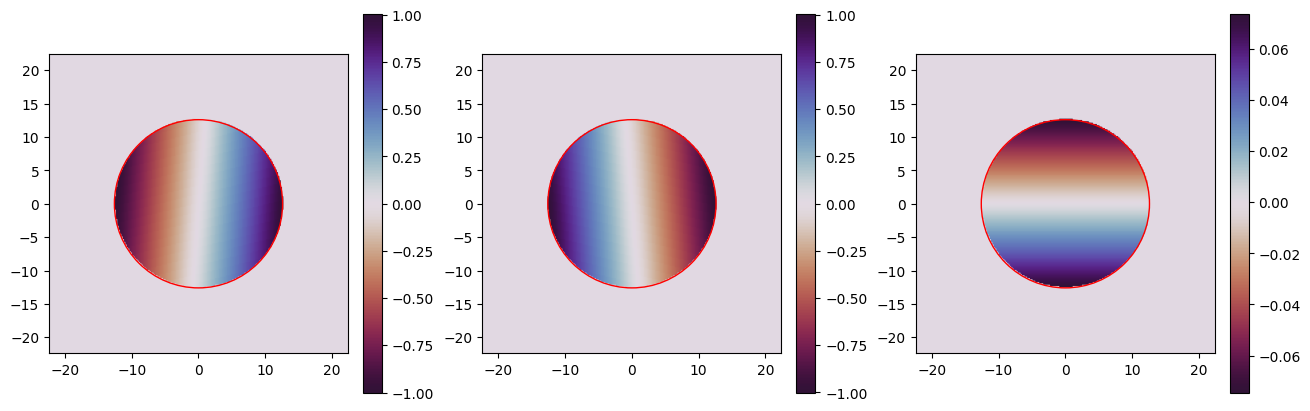

In [180]:
fig0, ax0 = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")

# img = ax0[0].imshow(np.rot90(yan*mask2) - rot_xan*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), cmap=cmap)
img = ax0[0].imshow(rot_xan1*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), cmap=cmap)
circle = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[0].add_patch(circle)
plt.colorbar(img, ax=ax0[0])
img = ax0[1].imshow((-rot_xan2)*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), cmap=cmap)
circle = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[1].add_patch(circle)
plt.colorbar(img, ax=ax0[1])
# img = ax0[2].imshow((xan*mask2 - rot_xan*mask2), extent=(-imgsize,imgsize,-imgsize,imgsize), cmap=cmap)
img = ax0[2].imshow((rot_xan1*mask2 + (-rot_xan2)*mask2)/2, extent=(-imgsize,imgsize,-imgsize,imgsize), cmap=cmap)
circle = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[2].add_patch(circle)
plt.colorbar(img, ax=ax0[2])
# fig0.colorbar(mappable=img)

# print(np.nanmax((np.rot90(yan*mask2) - rot_xan*mask2)[:]))
# print(np.nanmax(xan*mask2[:]))
# print(np.nanmax(rot_xan*mask2[:]))
# print(np.nanmax((xan*mask2 - rot_xan*mask2)[:]))

print(np.nanmax((rot_xan1*mask2)[:]))
print(np.nanmax((rot_xan1*mask2 - rot_xan2*mask2)[:])/2)


plt.savefig('rotvel_tgx.svg')

Probe values at a given perimeter

In [17]:
def get_discrete_circle_coords_from_coordinates(
    center_coord, radius, x_coords, y_coords, num_points=360
):
    """
    Get image indices (row, col) along a circle defined in coordinate space.

    Parameters:
        center_coord (tuple): (y_coord, x_coord) center in coordinate space
        radius (float): Radius in coordinate units
        x_coords (1D array): x-coordinates of the image grid (cols)
        y_coords (1D array): y-coordinates of the image grid (rows)
        num_points (int): Points along the circle

    Returns:
        indices (ndarray): Unique (row, col) indices into image
    """
    # Generate circle in coordinate space
    angles = np.linspace(0, 2 * np.pi, num_points, endpoint=False)
    y_circle = center_coord[0] + radius * np.sin(angles)
    x_circle = center_coord[1] + radius * np.cos(angles)

    # Find closest index in the grid for each point
    row_indices = np.searchsorted(y_coords, y_circle)
    col_indices = np.searchsorted(x_coords, x_circle)

    # Clip to valid index range
    row_indices = np.clip(row_indices, 0, len(y_coords) - 1)
    col_indices = np.clip(col_indices, 0, len(x_coords) - 1)

    coords = np.vstack((row_indices, col_indices)).T

    # Remove duplicates
    coords = np.unique(coords, axis=0)

    return coords

def sort_circle_coords_by_angle(coords, x_coords, y_coords, center_coord):
    """
    Sort (row, col) indices of a circle based on angular position around center.

    Parameters:
        coords (ndarray): (row, col) indices of sampled circle
        x_coords (1D array): full x-coordinate axis
        y_coords (1D array): full y-coordinate axis
        center_coord (tuple): (y_coord, x_coord) in coordinate space

    Returns:
        sorted_indices (ndarray): (row, col) sorted by angle
        angles (ndarray): corresponding angles in radians
    """
    # Convert indices to coordinate space
    y = y_coords[coords[:, 0]]
    x = x_coords[coords[:, 1]]

    # Compute angles relative to center
    angles = np.arctan2(y - center_coord[0], x - center_coord[1])
    
    # Sort by angle
    sort_idx = np.argsort(angles)
    sorted_coords = coords[sort_idx]
    sorted_angles = angles[sort_idx]
    
    return sorted_coords, sorted_angles


In [18]:
def sample_from_image_at_coords(image, coords):
    return image[coords[:, 0], coords[:, 1]]

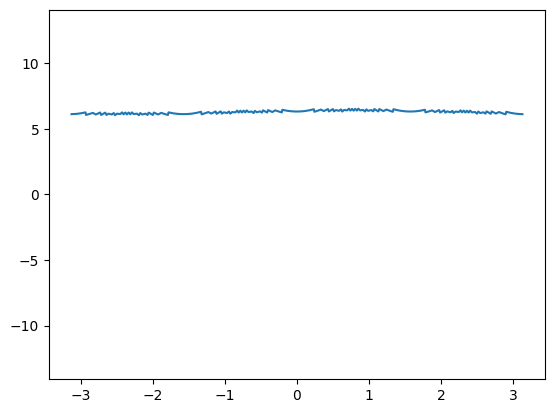

In [19]:
x_coords = np.linspace(-imgsize,imgsize,shape)
y_coords = np.linspace(-imgsize,imgsize,shape)

# Get indices of circle
coords = get_discrete_circle_coords_from_coordinates(
    center_pre, r_phan*0.5, x_coords, y_coords, num_points=500
)

# Sort them by angle
sorted_coords, sorted_angles = sort_circle_coords_by_angle(
    coords, x_coords, y_coords, center_pre
)

# values = xan[sorted_coords[:, 0], sorted_coords[:, 1]]
values = np.sqrt(xan**2+yan**2)[sorted_coords[:, 0], sorted_coords[:, 1]]

# Plot
# plt.imshow(xan, extent=[x_coords[0], x_coords[-1], y_coords[-1], y_coords[0]], cmap='gray')
# plt.plot(xan[coords[:, 1]], yan[coords[:, 0]], 'r')
# plt.title("Coordinate-space circle on image")

plt.plot(sorted_angles, values)
plt.ylim((-14.1, 14.1))
plt.show()

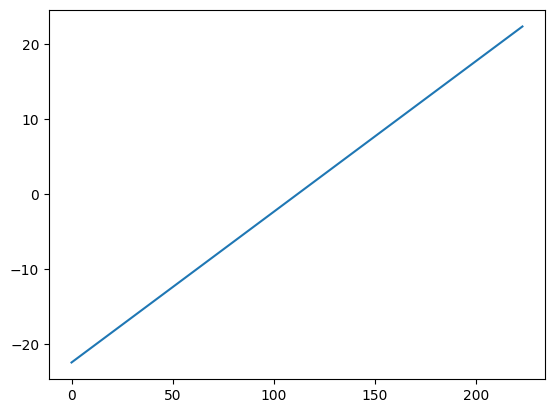

In [20]:
values = xan[shape//2, :]

plt.plot(values)
plt.show()

In [21]:
xan.shape

(224, 224)

In [22]:
# Convert indices to coordinate values
y_probed = np.linspace(-imgsize,imgsize,shape)[coords[:, 0]]
x_probed = np.linspace(-imgsize,imgsize,shape)[coords[:, 1]]

143
22.4
(224, 224)


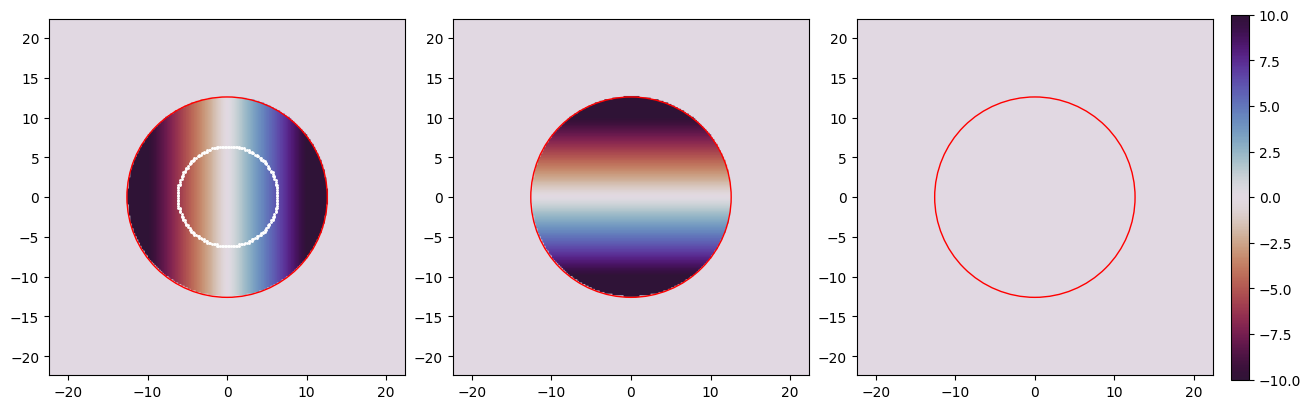

In [23]:
fig0, ax0 = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")

# ax0[0].imshow(np.sqrt(xan**2+yan**2), extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-10, vmax=10, cmap=cmap)
# circle = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
# ax0[0].add_patch(circle)

ax0[0].imshow(xan*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-10, vmax=10, cmap=cmap)
circle = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[0].add_patch(circle)
ax0[0].plot(x_probed, y_probed, 'w.', markersize=2, label="Probed Points")

print(np.max(coords))
print(imgsize)
print(xan.shape)

ax0[1].imshow(yan*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-10, vmax=10, cmap=cmap)
circle2 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[1].add_patch(circle2)

im2 = ax0[2].imshow(xan*mask2 - xanccw*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-10, vmax=10, cmap=cmap)
circle3 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[2].add_patch(circle3)

fig0.colorbar(im2)
plt.show()

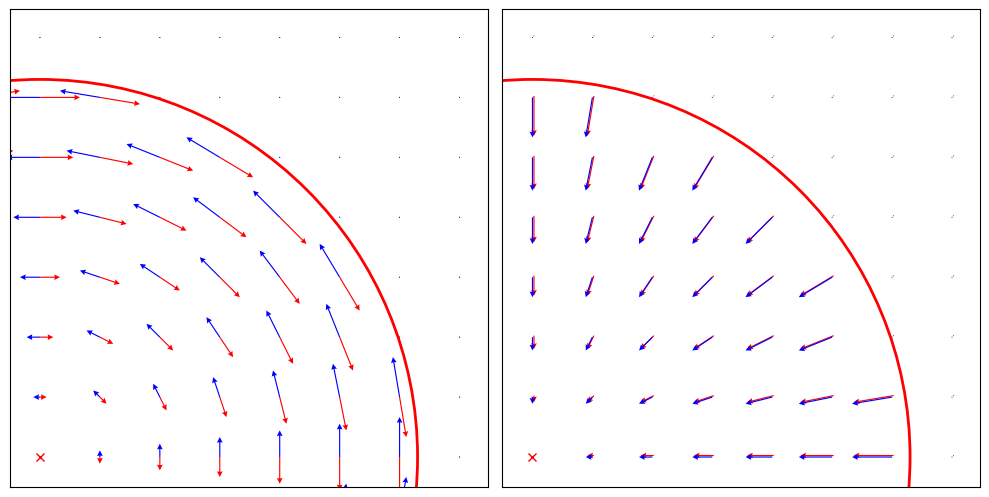

In [80]:
## CALCULATIONS # Pfeile innen müssten kürzer sein!!
# r_pre = np.array(np.linspace(-r_phan,r_phan,66))

# U=2pi*r, (rpm)*min/60s=(2pi*r)/60s ==> v=2pi*r/60
center_pre = (0, 0) # Circle center

# VELOCITY
size = 30
# xan,yan = np.meshgrid(np.linspace(-imgsize,imgsize,size),np.linspace(-imgsize,imgsize,size))
xan,yan = np.meshgrid(np.arange(-size,size, 2),np.arange(-size,size, 2))
distances = np.sqrt(xan**2 + yan**2)
angles = np.arctan2(yan, xan) #angles from each point to center
rotation = distances * 10
center_rotation = np.pi / 2  # 90 degrees (pi/2) rotation for a full circle
uan = np.cos(angles + center_rotation) * distances
van = np.sin(angles + center_rotation) * distances
# uan = yan/np.sqrt(xan**2 + yan**2)
# van = -xan/np.sqrt(xan**2 + yan**2)

# ACCELERATION
u2an = -xan
v2an = -yan

# MASKING
dist_from_center2 = np.sqrt(xan**2 + yan**2)
mask2 = dist_from_center2 <= r_phan
uan = mask2*uan
van = mask2*van
u2an = mask2*u2an
v2an = mask2*v2an

## PLOTTING predicted velocity and acceleration
# analytical circle
circle2 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False, linewidth=2)
circle4 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False, linewidth=2)
circle5 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False, linewidth=2)

fig0, ax0 = plt.subplots(1, 2, figsize=(10, 7), sharex=True, sharey=True)

ax0[0].quiver(xan,yan,-uan,-van, scale=size, units='inches', headwidth=5, headlength=5, color='r')
ax0[0].quiver(xan,yan,uan,van, scale=size, units='inches', headwidth=5, headlength=5, color='b')
# ax0[0].axline([0, 0], [1, 1], color='grey')
ax0[0].add_patch(circle2)
ax0[0].plot(center_pre[0], center_pre[1], 'xr')
# ax0[0].set_title('(A)', loc='center')

ax0[1].quiver(xan+0.05,yan+0.05,u2an,v2an, scale=size, units='inches', headwidth=5, headlength=5, color='r')
ax0[1].quiver(xan,yan,u2an,v2an, scale=size, units='inches', headwidth=5, headlength=5, color='b')
ax0[1].add_patch(circle5)
# ax0[1].axline([0, 0], [1, 1], color='grey')
ax0[1].plot(center_pre[0], center_pre[1], 'xr')
# ax0[1].set_title('(C)', loc='center')
# ax0[2].set_title('Predicted velocity CW+CCW')


# ax0[0].quiver(xan,yan,-uan,-van, scale=size, units='inches', headwidth=5, headlength=5)
# ax0[0].add_patch(circle2)
# ax0[0].plot(center_pre[0], center_pre[1], 'xr')
# ax0[0].set_title('(A)', loc='center')
# # ax0[0].set_title('Predicted velocity CW')

# ax0[1].quiver(xan,yan,uan,van, scale=size, units='inches', headwidth=5, headlength=5)
# ax0[1].add_patch(circle4)
# ax0[1].plot(center_pre[0], center_pre[1], 'xr')
# ax0[1].set_title('(B)', loc='center')
# # ax0[1].set_title('Predicted velocity CCW')

# ax0[2].quiver(xan,yan,u2an,v2an, scale=size, units='inches', headwidth=5, headlength=5)
# ax0[2].add_patch(circle5)
# ax0[2].plot(center_pre[0], center_pre[1], 'xr')
# ax0[2].set_title('(C)', loc='center')
# # ax0[2].set_title('Predicted velocity CW+CCW')

for i in range(2):
    ax0[i].set_aspect('equal')
    # ax0[i].set_xlabel(r'x [1 $\cdot 10^{-2}$ m]')
    ax0[i].set_xlim(-imgsize,imgsize)
    ax0[i].set_ylim(-imgsize,imgsize)
    ax0[i].grid(color='silver', linestyle='--', linewidth=0.5)
    ax0[i].spines['bottom'].set_color('k')
    ax0[i].spines['left'].set_color('k')
    ax0[i].spines['right'].set_color('k')
    ax0[i].spines['top'].set_color('k')
    ax0[i].set_xticks([])
    ax0[i].set_yticks([])
# ax0[0].set_ylabel(r'y [1 $\cdot 10^{-2}$ m]')
# ax0[1].set_yticks([])
# ax0[2].set_yticks([])

ax0[0].set_xlim(-1,imgsize/1.5)
ax0[0].set_ylim(-1,imgsize/1.5)

fig0.tight_layout()

plt.savefig('quiver_analytical.svg')
plt.show()

# # Only save inside of the figure
# extent = ax0[2].get_window_extent().transformed(fig0.dpi_scale_trans.inverted())
# fig0.savefig('figs/ax2_figure.png', bbox_inches=extent.expanded(1.01, 0.96))

# save the plot to tikz file
# tpl.clean_figure()
# savepath = savefigpath + r'\vectorfields\predicted.tikz'
# tpl.save(savepath) #, axis_width=r'\figwidth', axis_height=r'\figheight'

